This test is on
1. i.i.d. rayleigh fading channel
2. 4*4 MIMO channel
3. 1000 symbols per channel
4. total of 1000 channels


In [ ]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!cd /content
!rm -rf EE_MIMO_PROJECT
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

In [ ]:
# import models
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP(verbose=False)
}

In [ ]:
# mimo settings
import torch
from src.channel.rayleighfading import rayleighfading
BLOCKS = 100000
SYMBOLS_PER_CHANNEL = 1
# total of (SYMBOLS_PER_CHANNEL * BLOCKS) symbols are transmitted
NT = 4
NR = 4
SNR_DB = list(range(0, 22, 2))

def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)

qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
gray = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])

In [ ]:
from src.channel.testbench import Testbench
bench = Testbench(models, qpsk, gray, SYMBOLS_PER_CHANNEL, SNR_DB)
csi = torch.stack([generateChannel(NR=NR, NT=NT) for _ in range(BLOCKS)])
ber, bits_per_snr = bench.run(csi)

print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

currently running block: 0 to 100
currently running block: 100 to 200
currently running block: 200 to 300
currently running block: 300 to 400
currently running block: 400 to 500
currently running block: 500 to 600
currently running block: 600 to 700
currently running block: 700 to 800
currently running block: 800 to 900
currently running block: 900 to 1000
currently running block: 1000 to 1100
currently running block: 1100 to 1200
currently running block: 1200 to 1300
currently running block: 1300 to 1400
currently running block: 1400 to 1500
currently running block: 1500 to 1600
currently running block: 1600 to 1700
currently running block: 1700 to 1800
currently running block: 1800 to 1900
currently running block: 1900 to 2000
currently running block: 2000 to 2100
currently running block: 2100 to 2200
currently running block: 2200 to 2300
currently running block: 2300 to 2400
currently running block: 2400 to 2500
currently running block: 2500 to 2600
currently running block: 2600 to 

Downward triangles: zero observed errors, shown at 1 / bits per SNR.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

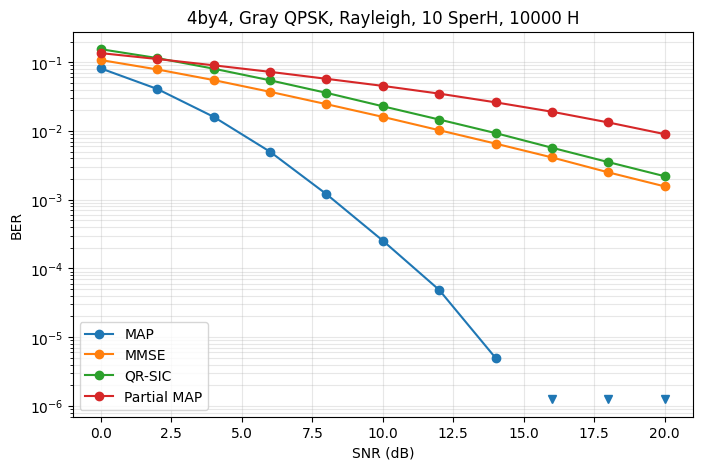

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    points = ber[:, j]
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            np.full(zero.sum(), 1 / bits_per_snr),
            "v",
            color=line.get_color(),
        )

TITLE = f"{NT}by{NR}, Gray QPSK, Rayleigh, {SYMBOLS_PER_CHANNEL} SperH, {BLOCKS} H"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at 1 / bits per SNR.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
files.download(f'{TITLE}.png')

plt.show()